# 25. Canal semántico del bloqueador: qué ganaría y qué costaría

**Autor:** Jason Sepúlveda S.
**Proyecto:** Evaluación experimental de la extracción automática y la representación
persistente de decisiones organizacionales frente a Recuperación Aumentada (RAG)
**Depende de:** [`18-jss-anotacion-f2-adjudicacion.ipynb`](18-jss-anotacion-f2-adjudicacion.ipynb)
(§8: recall del bloqueador) · [manual de anotación](../docs/anotacion/manual-anotacion-oe1.md) ·
[`tareas-jss.md` §5](../docs/anotacion/asignacion/tareas-jss.md)

**Estado: completo. Es una medición, no una decisión.** El notebook mide qué aportaría un canal
semántico (similitud coseno entre embeddings) añadido al bloqueador léxico de la Tarea B y cuánto
costaría anotar los pares nuevos. No elige un umbral y no recomienda un camino. La decisión la
tomó `jss` el 2026-11-03 y quedó escrita en el ADR 0020, con estas cifras a la vista.

---

> **Aviso de alcance (ADR 0005).** ES2016, IS1003, TS3005 y el resto de las series que no son de
> desarrollo son series de **evaluación**. Este notebook muestra solo **identificadores,
> conteos y medidas agregadas** (puntajes, tokens compartidos, similitudes, tasas). **No muestra
> ni cita** frases de decisión de ninguna serie, tampoco las de IS1004 (serie de desarrollo), para
> mantener un mismo criterio. Los textos se embeben en memoria y en un archivo de caché que solo
> guarda vectores bajo una huella del texto (carpeta ignorada por git).

## Qué hace este notebook

1. Recuerda el resultado de la Tarea C y la regla prerregistrada que obliga a escribir una
   decisión (§1).
2. Reconstruye los pares de decisiones de las 14 series con su puntaje léxico, su similitud coseno
   y la etiqueta humana disponible (§2).
3. Describe, solo con medidas estructurales, los 6 falsos negativos de la Tarea C (§3).
4. Mide, para una grilla de umbrales de similitud coseno, qué atraparía el canal y qué costaría (§4).
5. Hace la misma medición aflojando el propio umbral léxico, como punto de comparación (§5).
6. Deja escritos los límites de la medición (§6) y una lectura factual, sin recomendación (§7).

## Qué NO hace este notebook

- **No cambia el bloqueador.** `blocking.py` conserva su punto de operación (0,30 y 2 tokens).
- **No elige un umbral.** Cualquier umbral que parezca el mejor aquí está elegido sobre los
  mismos 6 falsos negativos con que se evalúa (§6).
- **No anota ni agrega etiquetas.** Los pares nuevos que un canal semántico agregaría no tienen
  etiqueta; solo se cuentan.

---

# 1. Por qué se mide esto

El notebook 18 (§8) estimó el recall del bloqueador léxico con cuatro muestras de 50 pares
rechazados (IS1004, ES2016, IS1003 y TS3005). Aparecieron 6 falsos negativos en 200 pares y el
recall total quedó bajo 0,5.

La regla prerregistrada de [`tareas-jss.md` §5](../docs/anotacion/asignacion/tareas-jss.md) dice
que, si los falsos negativos son muchos en un sitio, **el punto de operación del bloqueador es el
problema y lo que toca es revisarlo, no muestrear más**; y que cualquiera sea la decisión, se
escribe (entrada en el registro de decisiones si cambia una cifra publicada, ADR si cambia el
procedimiento). Ya se decidió no pedir una muestra adicional.

Quedan dos caminos de procedimiento:

- **Camino 1.** Conservar el bloqueador léxico y declarar la pérdida como limitación.
- **Camino 2.** Agregar un canal semántico (embeddings) que proponga pares que el bloqueador
  léxico descarta, y anotar los pares nuevos.

Para decidir con evidencia versionada hace falta saber cuántos falsos negativos atraparía el
canal, a qué precio en pares por anotar y con cuántas falsas alarmas. Eso es lo que mide este
notebook. Las cifras salen de `afg.annotation.semantic_channel` (con tests), no de cálculos en
las celdas.

# 2. Insumos: pares, puntaje léxico, similitud coseno y etiquetas

In [1]:
import pandas as pd
from IPython.display import Markdown, display

from afg.annotation.blocking import _decision_text, decisions_from_abstractive
from afg.annotation.recall import recall_report
from afg.annotation.semantic_channel import (
    DEFAULT_THRESHOLDS,
    embed_texts,
    evaluate_channel,
    false_negative_diagnosis,
    lexical_sensitivity,
    read_gold_labels,
    read_recall_sample_labels,
    score_pairs,
    threshold_table,
)
from afg.annotation.workspace import WorkspacePaths, load_annotation_plan
from afg.audit.blocker import funnel_hours
from afg.conditions.c1_retrieval import OllamaEmbedder
from afg.eda.figures import plot_semantic_channel, report_style
from afg.eda.tables import format_thousands as es
from afg.experiments.pinned_environment import check_pinned_environment
from afg.experiments.provenance import LiveProbe
from afg.shared.config import load_corpus_config
from afg.shared.paths import AMI_DIR, INTERIM_DIR

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Guard: the corpus is gitignored.
if not AMI_DIR.exists() or not any(AMI_DIR.glob("abstractive/*.xml")):
    raise SystemExit("Falta el corpus AMI. Ejecuta primero: uv run afg corpus download")

SERIES = list(load_corpus_config()["oe1"]["series"])
PLAN = load_annotation_plan()
PATHS = WorkspacePaths()
SAMPLE_OWNER = PLAN.recall_sample.owner
SAMPLE_SERIES = list(PLAN.recall_sample.series_ids)
CACHE = INTERIM_DIR / "semantic-channel" / "bge-m3-decision-embeddings.json"
print(f"Series: {len(SERIES)}; muestras de recall: {', '.join(SAMPLE_SERIES)}")
print(f"Anotador de las muestras: {SAMPLE_OWNER}")

Series: 14; muestras de recall: IS1004, ES2016, IS1003, TS3005
Anotador de las muestras: gv


In [2]:
# The embedding model and its digest are the ones pinned in config/experiments.toml. The check
# stops here, before any model call, if the installed environment differs from the pins.
EMBEDDER = OllamaEmbedder.from_config()
PIN = check_pinned_environment(LiveProbe(), models=[EMBEDDER.model], needs_openkos=False)
print(f"Modelo de embeddings: {EMBEDDER.model}")
PINNED = PIN["pinned_environment"]
print(
    f"Entorno fijado verificado: {PIN['pinned_environment_ok']}; Ollama {PINNED['ollama_version']}"
)

DECISIONS = {s: decisions_from_abstractive(AMI_DIR, s) for s in SERIES}
TEXTS = [_decision_text(d) for ds in DECISIONS.values() for d in ds]
VECTORS = embed_texts(TEXTS, EMBEDDER, CACHE, model=EMBEDDER.model)

RECORDS = []
for series_id in SERIES:
    labels = {
        **read_gold_labels(series_id),
        **read_recall_sample_labels(series_id, SAMPLE_OWNER),
    }
    RECORDS += score_pairs(DECISIONS[series_id], VECTORS, labels)

N_DECISIONS = sum(len(ds) for ds in DECISIONS.values())
N_PAIRS = len(RECORDS)
N_CAND = sum(r.lexical_candidate for r in RECORDS)
N_REJECTED = N_PAIRS - N_CAND
N_LABELLED_CAND = sum(r.lexical_candidate and r.label is not None for r in RECORDS)
N_SAMPLED = sum((not r.lexical_candidate) and r.label is not None for r in RECORDS)
N_FN = sum(r.is_false_negative for r in RECORDS)
N_KEPT = sum(r.is_kept_relation for r in RECORDS)
print(
    f"{N_DECISIONS} decisiones; {N_PAIRS} pares entre reuniones distintas; "
    f"{N_CAND} candidatos léxicos y {N_REJECTED} rechazados."
)
print(
    f"Etiquetas: {N_LABELLED_CAND} candidatos con etiqueta (referencia), "
    f"{N_KEPT} con relación real; {N_SAMPLED} pares rechazados muestreados, "
    f"{N_FN} falsos negativos."
)

Modelo de embeddings: bge-m3
Entorno fijado verificado: True; Ollama 0.32.9


343 decisiones; 3071 pares entre reuniones distintas; 92 candidatos léxicos y 2979 rechazados.
Etiquetas: 92 candidatos con etiqueta (referencia), 46 con relación real; 200 pares rechazados muestreados, 6 falsos negativos.


Antes de usar las cifras se comprueba que esta reconstrucción coincide con la del notebook 18:
mismo número de candidatos, mismos falsos negativos y mismo recall léxico que `recall_report`.

In [3]:
RECALL = recall_report(SAMPLE_SERIES, SAMPLE_OWNER, paths=PATHS).total
BASE = evaluate_channel(RECORDS, lambda r: False, name="solo léxico", parameter=None)

checks = {
    "candidatos léxicos = 92": N_CAND == 92,
    "muestreados = n de recall_report": RECALL.n_sampled == N_SAMPLED,
    "falsos negativos = los de recall_report": RECALL.n_false_negative == N_FN,
    "conservadas (4 series) = las de recall_report": RECALL.kept_relations
    == BASE.kept_total_sampled,
    "recall léxico = el de recall_report": abs(BASE.lexical_recall - RECALL.recall) < 1e-9,
}
for name, ok in checks.items():
    print(("OK   " if ok else "FALLA"), name)
assert all(checks.values())

display(
    Markdown(
        f"""
**Comprobación superada.** Se reproduce el recall léxico del notebook 18:
**{es(RECALL.recall, 3)}** [{es(RECALL.recall_lower, 3)}; {es(RECALL.recall_upper, 3)}], con
{es(RECALL.missed, 1)} relaciones perdidas estimadas frente a {RECALL.kept_relations} conservadas
en las cuatro series muestreadas. Las {es(BASE.kept_total_all)} relaciones conservadas de las 14
series incluyen las de las series sin muestra de recall."""
    )
)

OK    candidatos léxicos = 92
OK    muestreados = n de recall_report
OK    falsos negativos = los de recall_report
OK    conservadas (4 series) = las de recall_report
OK    recall léxico = el de recall_report



**Comprobación superada.** Se reproduce el recall léxico del notebook 18:
**0,407** [0,245; 0,596], con
26,3 relaciones perdidas estimadas frente a 18 conservadas
en las cuatro series muestreadas. Las 46 relaciones conservadas de las 14
series incluyen las de las series sin muestra de recall.

# 3. Diagnóstico de los 6 falsos negativos

Para cada falso negativo se muestran **solo medidas estructurales**: el coeficiente de
solapamiento léxico, los tokens compartidos, la similitud coseno y la posición de ese par dentro
de los pares rechazados de su serie. La posición es el porcentaje de pares rechazados de la serie
con una similitud coseno **mayor o igual**: cuanto menor, más arriba está el par en el ranking
semántico y más fácil sería aislarlo.

El bloqueador exige un coeficiente de al menos 0,30 **y** al menos 2 tokens compartidos.

In [4]:
CLASS_ES = {"zero_overlap": "sin solapamiento", "partial_overlap": "solapamiento parcial"}
DIAG = false_negative_diagnosis(RECORDS)
diag_df = pd.DataFrame(
    {
        "serie": [d.series_id for d in DIAG],
        "par (anterior → posterior)": [f"{d.earlier_id} → {d.later_id}" for d in DIAG],
        "solapamiento": [d.overlap_score for d in DIAG],
        "tokens compartidos": [d.shared_tokens for d in DIAG],
        "clase": [CLASS_ES[d.overlap_class] for d in DIAG],
        "similitud coseno": [d.cosine for d in DIAG],
        "posición en la serie (%)": [d.cosine_rank_share * 100 for d in DIAG],
    }
)
display(
    diag_df.style.format(
        {
            "solapamiento": "{:.3f}",
            "similitud coseno": "{:.3f}",
            "posición en la serie (%)": "{:.1f}",
        },
        decimal=",",
    ).hide(axis="index")
)
N_ZERO = sum(d.overlap_class == "zero_overlap" for d in DIAG)
N_PARTIAL = len(DIAG) - N_ZERO
COS_MIN, COS_MAX = min(d.cosine for d in DIAG), max(d.cosine for d in DIAG)
ZERO_COS = [d.cosine for d in DIAG if d.overlap_class == "zero_overlap"]
PART_COS = [d.cosine for d in DIAG if d.overlap_class == "partial_overlap"]
ZERO_MIN, ZERO_MAX, PART_MIN, PART_MAX = min(ZERO_COS), max(ZERO_COS), min(PART_COS), max(PART_COS)
POS_MIN, POS_MAX = min(d.cosine_rank_share for d in DIAG), max(d.cosine_rank_share for d in DIAG)

serie,par (anterior → posterior),solapamiento,tokens compartidos,clase,similitud coseno,posición en la serie (%)
IS1004,IS1004b.d02 → IS1004d.d01,"0,000",0,sin solapamiento,"0,579","17,4"
IS1004,IS1004b.d02 → IS1004d.d11,"0,167",1,solapamiento parcial,"0,596","12,5"
IS1004,IS1004b.d05 → IS1004c.d01,"0,000",0,sin solapamiento,"0,537","30,4"
TS3005,TS3005a.d01 → TS3005b.d12,"0,000",0,sin solapamiento,"0,520","60,6"
TS3005,TS3005b.d15 → TS3005c.d01,"0,333",1,solapamiento parcial,"0,806","2,8"
TS3005,TS3005c.d02 → TS3005d.d01,"0,250",1,solapamiento parcial,"0,796","3,1"


In [5]:
display(
    Markdown(
        f"""
**Lectura.**

- **{N_ZERO} de {len(DIAG)} no comparten ningún token de contenido** (coeficiente 0): ningún
  ajuste del umbral léxico puede recuperarlos, porque no hay solapamiento que aflojar.
- **{N_PARTIAL} de {len(DIAG)} comparten un solo token.** El umbral de tokens (2) los descarta
  aunque en algunos casos el coeficiente sí supera 0,30; la columna «solapamiento» lo permite ver.
- La similitud coseno de los falsos negativos va de **{es(COS_MIN, 3)}** a **{es(COS_MAX, 3)}**.
  Los que no comparten ningún token van de {es(ZERO_MIN, 3)} a {es(ZERO_MAX, 3)}; los que
  comparten uno, de {es(PART_MIN, 3)} a {es(PART_MAX, 3)}.
- **Posición en el ranking de su serie:** entre el {es(POS_MIN * 100, 1)} % y el
  {es(POS_MAX * 100, 1)} % de los pares rechazados tiene una similitud igual o mayor. Un par con
  posición alta (porcentaje grande) no se aísla con ningún umbral razonable sin traer consigo a
  muchos otros."""
    )
)


**Lectura.**

- **3 de 6 no comparten ningún token de contenido** (coeficiente 0): ningún
  ajuste del umbral léxico puede recuperarlos, porque no hay solapamiento que aflojar.
- **3 de 6 comparten un solo token.** El umbral de tokens (2) los descarta
  aunque en algunos casos el coeficiente sí supera 0,30; la columna «solapamiento» lo permite ver.
- La similitud coseno de los falsos negativos va de **0,520** a **0,806**.
  Los que no comparten ningún token van de 0,520 a 0,579; los que
  comparten uno, de 0,596 a 0,806.
- **Posición en el ranking de su serie:** entre el 2,8 % y el
  60,6 % de los pares rechazados tiene una similitud igual o mayor. Un par con
  posición alta (porcentaje grande) no se aísla con ningún umbral razonable sin traer consigo a
  muchos otros.

# 4. Tabla de umbrales del canal semántico

El canal semántico propone, además de los candidatos léxicos, todo par rechazado cuya similitud
coseno entre los textos de las dos decisiones (el mismo texto con que bloquea el léxico) sea al
menos `t`. Para cada `t` de la grilla, `semantic_channel.threshold_table` calcula:

- **a. Falsos negativos recuperados** de los 6 de la Tarea C.
- **b. Relaciones conservadas que el canal también detectaría** (solapamiento con el canal
  léxico), en las 14 series y en las 4 series muestreadas.
- **c. Falsas alarmas:** pares rechazados muestreados y etiquetados `no_relacionada` que el
  canal marcaría, con el intervalo de Wilson al 95 %.
- **d. Costo de anotación:** pares nuevos (rechazados por el léxico con similitud ≥ `t`) y total de
  candidatos (92 más los nuevos). Las horas suponen 1,5 minutos por par y **una** pasada de
  anotación (una persona); el protocolo anota cada par dos veces.
- **e. Recall estimado de la unión** (léxico O semántico) con la misma lógica estratificada de
  `recall_report`: relaciones perdidas estimadas × fracción de falsos negativos que el canal
  atrapa. **Descansa en 6 falsos negativos** (ver §6).

In [6]:
ROWS = threshold_table(RECORDS)
BY_T = {r.parameter: r for r in ROWS}


def ci(low, high):
    return f"[{es(low, 3)}; {es(high, 3)}]"


def table_row(r):
    base = r.parameter is None
    return {
        "umbral t": "solo léxico" if base else es(r.parameter, 2),
        "FN recuperados (de 6)": f"{r.fn_caught} de {r.fn_total}",
        "conservadas, 14 series": f"{r.kept_caught_all} de {r.kept_total_all}",
        "conservadas, 4 series": f"{r.kept_caught_sampled} de {r.kept_total_sampled}",
        "falsas alarmas": "n. a." if base else f"{r.false_alarms} de {r.sampled_no_relation}",
        "tasa de falsas alarmas": "n. a." if base else f"{es(r.false_alarm_rate * 100, 1)} %",
        "IC 95 % (Wilson)": "n. a." if base else ci(r.false_alarm_lower, r.false_alarm_upper),
        "pares nuevos": es(r.new_pairs),
        "candidatos totales": es(r.candidates_total),
        "horas de anotación (1 pasada)": es(funnel_hours([r.new_pairs])[0], 1),
        "recall de la unión": es(r.union_recall, 3),
        "IC 95 % recall": ci(r.union_recall_lower, r.union_recall_upper),
    }


table = pd.DataFrame([table_row(r) for r in [BASE, *ROWS]])
display(table.style.hide(axis="index"))

umbral t,FN recuperados (de 6),"conservadas, 14 series","conservadas, 4 series",falsas alarmas,tasa de falsas alarmas,IC 95 % (Wilson),pares nuevos,candidatos totales,horas de anotación (1 pasada),recall de la unión,IC 95 % recall
solo léxico,0 de 6,0 de 46,0 de 18,n. a.,n. a.,n. a.,0,92,"0,0","0,407","[0,245; 0,596]"
"0,50",6 de 6,46 de 46,18 de 18,139 de 194,"71,6 %","[0,649; 0,775]",2.087,2.179,"52,2","1,000","[0,733; 1,000]"
"0,55",4 de 6,46 de 46,18 de 18,109 de 194,"56,2 %","[0,492; 0,630]",1.522,1.614,"38,0","0,802","[0,535; 0,936]"
"0,60",2 de 6,41 de 46,17 de 18,83 de 194,"42,8 %","[0,360; 0,498]",1.050,1.142,"26,2","0,636","[0,404; 0,821]"
"0,65",2 de 6,35 de 46,14 de 18,58 de 194,"29,9 %","[0,239; 0,367]",681,773,"17,0","0,636","[0,404; 0,821]"
"0,70",2 de 6,33 de 46,14 de 18,25 de 194,"12,9 %","[0,089; 0,183]",392,484,"9,8","0,636","[0,404; 0,821]"
"0,75",2 de 6,32 de 46,13 de 18,5 de 194,"2,6 %","[0,011; 0,059]",149,241,"3,7","0,636","[0,404; 0,821]"
"0,80",1 de 6,21 de 46,10 de 18,2 de 194,"1,0 %","[0,003; 0,037]",34,126,"0,8","0,521","[0,322; 0,718]"
"0,85",0 de 6,12 de 46,7 de 18,0 de 194,"0,0 %","[0,000; 0,019]",3,95,"0,1","0,407","[0,245; 0,596]"
"0,90",0 de 6,8 de 46,4 de 18,0 de 194,"0,0 %","[0,000; 0,019]",0,92,"0,0","0,407","[0,245; 0,596]"


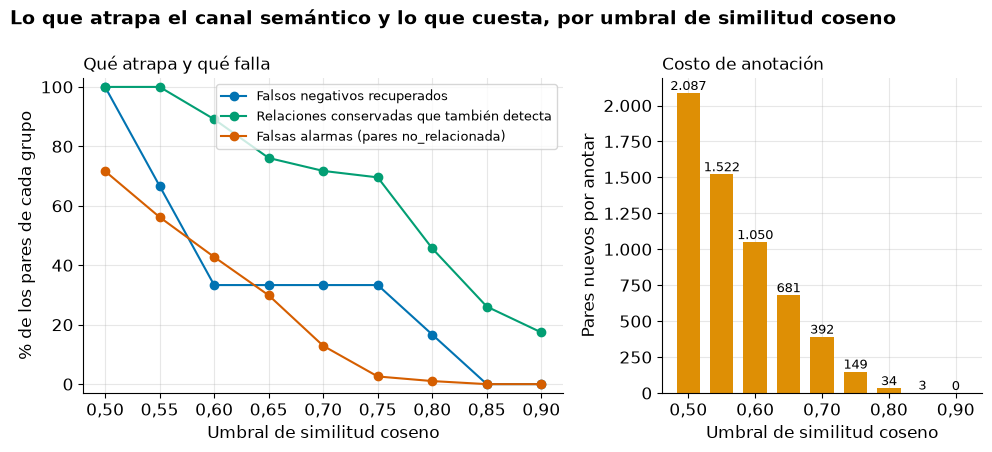

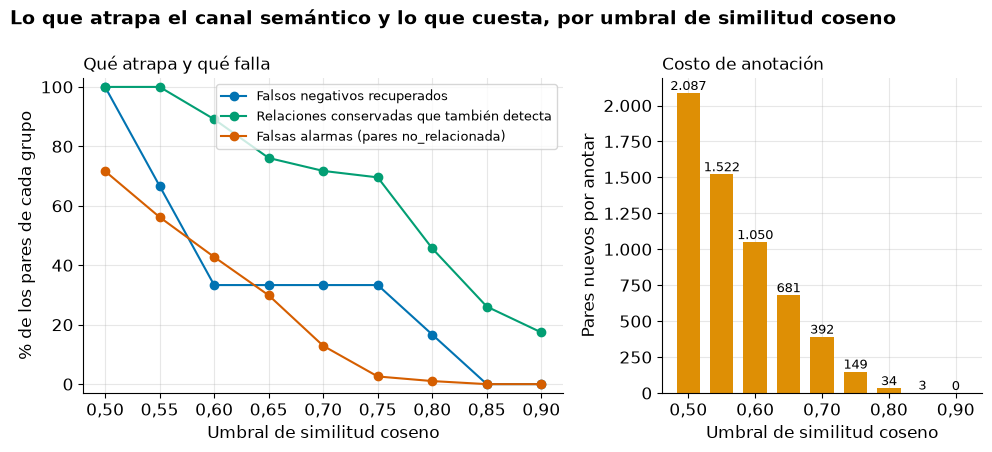

In [7]:
plot_rows = [
    (
        r.parameter,
        r.fn_caught / r.fn_total,
        r.kept_caught_all / r.kept_total_all,
        r.false_alarm_rate,
        r.new_pairs,
    )
    for r in ROWS
]
with report_style():
    fig = plot_semantic_channel(
        plot_rows,
        title="Lo que atrapa el canal semántico y lo que cuesta, por umbral de similitud coseno",
    )
    display(fig)

**Cómo leer la figura.** El panel izquierdo muestra, para cada umbral, qué porcentaje de los 6
falsos negativos recupera el canal (azul), qué porcentaje de las relaciones ya conservadas por el
bloqueador léxico detecta (verde, solapamiento) y qué porcentaje de los pares muestreados sin
relación marcaría como candidatos (rojo, falsas alarmas). El panel derecho muestra cuántos pares
nuevos habría que anotar. Las tres curvas bajan al subir el umbral: lo que se gana en pares por
anotar se pierde en falsos negativos recuperados.

## 4.1 Pares nuevos por serie

El costo de anotación no se reparte parejo entre series: depende de cuántas decisiones tiene
cada una. La tabla da los pares nuevos por serie para algunos umbrales de la grilla.

In [8]:
from collections import Counter

SHOW_T = [0.60, 0.70, 0.75, 0.80]
per_series = pd.DataFrame({f"t = {es(t, 2)}": BY_T[t].new_pairs_by_series for t in SHOW_T}).loc[
    SERIES
]
LEX_BY_SERIES = Counter(r.series_id for r in RECORDS if r.lexical_candidate)
per_series.insert(0, "candidatos léxicos", [LEX_BY_SERIES[s] for s in SERIES])
per_series.loc["Total"] = per_series.sum()
per_series.index.name = "serie"
display(per_series.style.format(lambda v: es(v)))

,candidatos léxicos,"t = 0,60","t = 0,70","t = 0,75","t = 0,80"
serie,,,,,
ES2002,9,147,68,32,7
ES2008,14,191,85,24,4
ES2014,14,48,8,2,0
ES2015,3,83,18,7,2
ES2016,4,129,43,12,3
IS1003,8,129,69,16,3
IS1004,4,19,2,0,0
IS1006,1,38,15,6,0
IS1008,8,12,1,0,0


# 5. Sensibilidad: aflojar el propio umbral léxico

Como punto de comparación, la misma medición para puntos de operación léxicos más laxos que el
actual (0,30 y 2 tokens), obtenidos con las funciones del bloqueador sin tocar sus valores por
defecto. Un par «nuevo» es uno que el punto de operación actual rechaza y el laxo conserva.

In [9]:
LEX_GRID = [(0.30, 2), (0.25, 2), (0.20, 2), (0.30, 1), (0.25, 1), (0.20, 1)]
LEX_ROWS = lexical_sensitivity(RECORDS, LEX_GRID)
lex_table = pd.DataFrame(
    [
        {
            "umbral léxico": es(t, 2),
            "tokens mínimos": m,
            "FN recuperados (de 6)": f"{r.fn_caught} de {r.fn_total}",
            "falsas alarmas": f"{r.false_alarms} de {r.sampled_no_relation}",
            "pares nuevos": es(r.new_pairs),
            "candidatos totales": es(r.candidates_total),
            "horas de anotación (1 pasada)": es(funnel_hours([r.new_pairs])[0], 1),
            "recall de la unión": es(r.union_recall, 3),
            "IC 95 % recall": ci(r.union_recall_lower, r.union_recall_upper),
        }
        for (t, m), r in zip(LEX_GRID, LEX_ROWS, strict=True)
    ]
)
display(lex_table.style.hide(axis="index"))
LEX = {g: r for g, r in zip(LEX_GRID, LEX_ROWS, strict=True)}

umbral léxico,tokens mínimos,FN recuperados (de 6),falsas alarmas,pares nuevos,candidatos totales,horas de anotación (1 pasada),recall de la unión,IC 95 % recall
"0,30",2,0 de 6,0 de 194,0,92,"0,0","0,407","[0,245; 0,596]"
"0,25",2,0 de 6,0 de 194,35,127,"0,9","0,407","[0,245; 0,596]"
"0,20",2,0 de 6,1 de 194,44,136,"1,1","0,407","[0,245; 0,596]"
"0,30",1,1 de 6,64 de 194,620,712,"15,5","0,521","[0,322; 0,718]"
"0,25",1,2 de 6,82 de 194,853,945,"21,3","0,636","[0,404; 0,821]"
"0,20",1,2 de 6,88 de 194,955,1.047,"23,9","0,636","[0,404; 0,821]"


In [10]:
loose = LEX[(0.30, 1)]
display(
    Markdown(
        f"""
**Lectura.**

- **Bajar solo el coeficiente** (0,25 o 0,20 con 2 tokens) agrega {es(LEX[(0.25, 2)].new_pairs)} y
  {es(LEX[(0.20, 2)].new_pairs)} pares, y recupera {LEX[(0.25, 2)].fn_caught} y
  {LEX[(0.20, 2)].fn_caught} de los 6 falsos negativos: ninguno de los 6 pasa a candidato porque
  todos tienen a lo sumo un token compartido.
- **Bajar el mínimo de tokens a 1** (con 0,30) recupera {loose.fn_caught} falso negativo, pero
  agrega {es(loose.new_pairs)} pares (de {es(loose.candidates_total)} candidatos en total) y marca
  {loose.false_alarms} de {loose.sampled_no_relation} pares muestreados sin relación. Es el
  régimen de oraciones cortas que el módulo del bloqueador describe como el motivo de exigir 2
  tokens.
- Los falsos negativos sin ningún token compartido ({N_ZERO} de 6) quedan fuera de **cualquier**
  punto de operación léxico de esta tabla."""
    )
)


**Lectura.**

- **Bajar solo el coeficiente** (0,25 o 0,20 con 2 tokens) agrega 35 y
  44 pares, y recupera 0 y
  0 de los 6 falsos negativos: ninguno de los 6 pasa a candidato porque
  todos tienen a lo sumo un token compartido.
- **Bajar el mínimo de tokens a 1** (con 0,30) recupera 1 falso negativo, pero
  agrega 620 pares (de 712 candidatos en total) y marca
  64 de 194 pares muestreados sin relación. Es el
  régimen de oraciones cortas que el módulo del bloqueador describe como el motivo de exigir 2
  tokens.
- Los falsos negativos sin ningún token compartido (3 de 6) quedan fuera de **cualquier**
  punto de operación léxico de esta tabla.

# 6. Límites de la medición

In [11]:
from collections import Counter

FN_BY_SERIES = Counter(r.series_id for r in RECORDS if r.is_false_negative)
NO_FN_SERIES = [s for s in SAMPLE_SERIES if FN_BY_SERIES[s] == 0]
N_NOREL = N_SAMPLED - N_FN
display(
    Markdown(
        f"""
- **{N_FN} falsos negativos.** Todo lo que depende de la tasa de falsos negativos (recuperados,
  recall de la unión) descansa en {N_FN} pares de {N_SAMPLED}. Los intervalos de la tabla reflejan
  solo la incertidumbre del muestreo de la Tarea C sobre los falsos negativos que el canal **no**
  recupera; no incluyen la incertidumbre de cuáles de ellos recupera.
- **Umbral explorado sobre los mismos datos.** Los umbrales se recorren sobre los mismos {N_FN}
  falsos negativos con que se evalúan. Cualquier umbral que parezca el mejor está elegido sobre
  los datos de evaluación, de modo que su rendimiento aquí es **optimista**. Por eso el notebook
  no elige ninguno.
- **Falsos negativos en pocas series.** {" y ".join(NO_FN_SERIES)} no aportan falsos negativos; la
  fracción recuperada se calcula solo sobre pares de {" y ".join(sorted(FN_BY_SERIES))}.
- **Las falsas alarmas se miden sobre pares muestreados.** Los {N_NOREL} pares sin relación son
  una muestra de los rechazados de {len(SAMPLE_SERIES)} series; la tasa solo da un orden de
  magnitud para los pares nuevos de las {len(SERIES)} series, no una cuenta.
- **Los pares nuevos no tienen etiqueta.** No se sabe cuántas relaciones reales contienen; el
  recall de la unión es una estimación a partir de la muestra, no una medición sobre los pares
  nuevos.
- **Un modelo y un texto.** Un solo modelo de embeddings (`{EMBEDDER.model}`, el fijado en
  `config/experiments.toml`) y un solo texto por decisión (el del bloqueador). Otro modelo u otro
  texto darían otras similitudes."""
    )
)


- **6 falsos negativos.** Todo lo que depende de la tasa de falsos negativos (recuperados,
  recall de la unión) descansa en 6 pares de 200. Los intervalos de la tabla reflejan
  solo la incertidumbre del muestreo de la Tarea C sobre los falsos negativos que el canal **no**
  recupera; no incluyen la incertidumbre de cuáles de ellos recupera.
- **Umbral explorado sobre los mismos datos.** Los umbrales se recorren sobre los mismos 6
  falsos negativos con que se evalúan. Cualquier umbral que parezca el mejor está elegido sobre
  los datos de evaluación, de modo que su rendimiento aquí es **optimista**. Por eso el notebook
  no elige ninguno.
- **Falsos negativos en pocas series.** ES2016 y IS1003 no aportan falsos negativos; la
  fracción recuperada se calcula solo sobre pares de IS1004 y TS3005.
- **Las falsas alarmas se miden sobre pares muestreados.** Los 194 pares sin relación son
  una muestra de los rechazados de 4 series; la tasa solo da un orden de
  magnitud para los pares nuevos de las 14 series, no una cuenta.
- **Los pares nuevos no tienen etiqueta.** No se sabe cuántas relaciones reales contienen; el
  recall de la unión es una estimación a partir de la muestra, no una medición sobre los pares
  nuevos.
- **Un modelo y un texto.** Un solo modelo de embeddings (`bge-m3`, el fijado en
  `config/experiments.toml`) y un solo texto por decisión (el del bloqueador). Otro modelo u otro
  texto darían otras similitudes.

# 7. Lectura

Lectura factual de las cifras anteriores. No recomienda un camino: la decisión es de `jss` y está
escrita en el ADR 0020.

In [12]:
RECALL_CI = ci(RECALL.recall_lower, RECALL.recall_upper)
LOW, MID, HIGH = BY_T[0.50], BY_T[0.75], BY_T[0.85]
LOW_CI, MID_CI = (
    ci(LOW.union_recall_lower, LOW.union_recall_upper),
    ci(MID.union_recall_lower, MID.union_recall_upper),
)
LOW_SHARE = es(LOW.new_pairs / N_REJECTED * 100, 1)
LOW_FACTOR, MID_FACTOR = es(LOW.candidates_total / N_CAND, 1), es(MID.candidates_total / N_CAND, 1)
T_ZERO = max(t for t in DEFAULT_THRESHOLDS if t <= ZERO_MIN)
ZERO_ROW = BY_T[T_ZERO]
display(
    Markdown(
        f"""
- **Camino 1 (conservar el bloqueador léxico).** Cuesta 0 pares nuevos: quedan {N_CAND}
  candidatos ({es(funnel_hours([N_CAND])[0], 1)} horas por pasada de anotación). El recall
  estimado es **{es(RECALL.recall, 3)}** {RECALL_CI}, con
  {es(RECALL.missed, 1)} relaciones perdidas estimadas frente a {RECALL.kept_relations}
  conservadas en las series muestreadas. La pérdida es una limitación declarada, sin cambiar la
  referencia ya anotada.
- **Camino 2 (agregar un canal semántico), umbral bajo.** Con t = 0,50 el canal recupera
  {LOW.fn_caught} de {LOW.fn_total} falsos negativos y el recall estimado de la unión es
  {es(LOW.union_recall, 3)} {LOW_CI}, pero agrega
  {es(LOW.new_pairs)} pares (total {es(LOW.candidates_total)}, {LOW_FACTOR}
  veces los actuales) y marca {LOW.false_alarms} de {LOW.sampled_no_relation} pares muestreados
  sin relación. Marca el {LOW_SHARE} % de los pares rechazados, de modo que filtra poco.
- **Camino 2, umbral intermedio.** Con t = 0,75 agrega {es(MID.new_pairs)} pares (total
  {es(MID.candidates_total)}, {MID_FACTOR} veces los actuales,
  {es(funnel_hours([MID.new_pairs])[0], 1)} horas adicionales por pasada), recupera
  {MID.fn_caught} de {MID.fn_total} falsos negativos y marca {MID.false_alarms} de
  {MID.sampled_no_relation} pares sin relación. El recall estimado de la unión sería
  {es(MID.union_recall, 3)} {MID_CI}. Es
  optimista por haber sido explorado sobre los mismos 6 falsos negativos (§6).
- **Camino 2, umbral alto.** Con t = 0,85 agrega {es(HIGH.new_pairs)} pares y recupera
  {HIGH.fn_caught} falsos negativos: el recall de la unión coincide con el léxico
  ({es(HIGH.union_recall, 3)}).
- **Los falsos negativos sin tokens en común.** Tienen una similitud coseno de {es(ZERO_MIN, 3)}
  a {es(ZERO_MAX, 3)}. El umbral de la grilla más alto que recupera a los tres es
  {es(T_ZERO, 2)}, con {es(ZERO_ROW.new_pairs)} pares nuevos y
  {es(ZERO_ROW.false_alarm_rate * 100, 1)} % de falsas alarmas.
- **Aflojar el umbral léxico** no recupera los falsos negativos sin tokens en común (§5) y, con
  1 token mínimo, agrega {es(loose.new_pairs)} pares.
- **Decisión tomada.** `jss` eligió el camino 1 el 2026-11-03 (ADR 0020): se mantiene el filtro
  léxico y la pérdida se declara como limitación. Estas cifras son la medición que respalda esa
  decisión y la base para reabrirla."""
    )
)


- **Camino 1 (conservar el bloqueador léxico).** Cuesta 0 pares nuevos: quedan 92
  candidatos (2,3 horas por pasada de anotación). El recall
  estimado es **0,407** [0,245; 0,596], con
  26,3 relaciones perdidas estimadas frente a 18
  conservadas en las series muestreadas. La pérdida es una limitación declarada, sin cambiar la
  referencia ya anotada.
- **Camino 2 (agregar un canal semántico), umbral bajo.** Con t = 0,50 el canal recupera
  6 de 6 falsos negativos y el recall estimado de la unión es
  1,000 [0,733; 1,000], pero agrega
  2.087 pares (total 2.179, 23,7
  veces los actuales) y marca 139 de 194 pares muestreados
  sin relación. Marca el 70,1 % de los pares rechazados, de modo que filtra poco.
- **Camino 2, umbral intermedio.** Con t = 0,75 agrega 149 pares (total
  241, 2,6 veces los actuales,
  3,7 horas adicionales por pasada), recupera
  2 de 6 falsos negativos y marca 5 de
  194 pares sin relación. El recall estimado de la unión sería
  0,636 [0,404; 0,821]. Es
  optimista por haber sido explorado sobre los mismos 6 falsos negativos (§6).
- **Camino 2, umbral alto.** Con t = 0,85 agrega 3 pares y recupera
  0 falsos negativos: el recall de la unión coincide con el léxico
  (0,407).
- **Los falsos negativos sin tokens en común.** Tienen una similitud coseno de 0,520
  a 0,579. El umbral de la grilla más alto que recupera a los tres es
  0,50, con 2.087 pares nuevos y
  71,6 % de falsas alarmas.
- **Aflojar el umbral léxico** no recupera los falsos negativos sin tokens en común (§5) y, con
  1 token mínimo, agrega 620 pares.
- **Decisión tomada.** `jss` eligió el camino 1 el 2026-11-03 (ADR 0020): se mantiene el filtro
  léxico y la pérdida se declara como limitación. Estas cifras son la medición que respalda esa
  decisión y la base para reabrirla.